# Machine Learning - Movie Ticket Dataset

## 1. Imports and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, SVR
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

clean_path = "../Output/clean_merged_movie_bookings.csv"
try:
    df = pd.read_csv(clean_path)
    print("Loaded cleaned merged data")
except FileNotFoundError:
    movies = pd.read_csv("../Dataset/Movie_Ticket_Assignment3_CSV1_Movies_Messy_500.csv")
    shows = pd.read_csv("../Dataset/Movie_Ticket_Assignment3_CSV2_Shows_Messy_500.csv")
    bookings = pd.read_csv("../Dataset/Movie_Ticket_Assignment3_CSV3_Bookings_Messy_500.csv")
    df = bookings.merge(shows, on="Show_ID", how="left").merge(movies, on="Movie_ID", how="left")
    print("Loaded and merged raw data")

print(df.shape)
display(df.head())

Loaded cleaned merged data
(513, 49)


,Booking_ID,Show_ID,Movie_ID,Booking_Date,Customer_ID,Customer_Age,Tickets,Final_Amount,Booking_Status,Customer_Name,...,Certificate,Duration_Minutes,Release_Date,Production_Budget_INR,Director,Rating,Movie_Status,Release_Year,Release_Month,Release_Month_Name
0,B00218,S0329,M020,2025-08-20,C0099,65.0,5.0,1530,Cancelled,Vivaan Shah,...,A,90.0,2025-01-17,161000000.0,K. Iyer,5.3,Completed,2025.0,1.0,January
1,B00240,S0255,M097,2026-04-20,C0131,61.0,3.0,1305,Confirmed,Aditya Mehta,...,U,185.0,2024-08-24,145000000.0,S. Kapoor,7.4,Active,2024.0,8.0,August
2,B00210,S0424,M178,2026-07-26,C0048,20.0,2.0,920,Cancelled,Priya Joshi,...,A,117.0,2024-05-25,104000000.0,M. Desai,8.7,Completed,2024.0,5.0,May
3,B00466,S0276,M333,2025-06-07,C0200,54.0,2.0,380,Confirmed,Sneha Sharma,...,A,142.0,2025-05-14,11000000.0,A. Mehta,7.1,Upcoming,2025.0,5.0,May
4,B00290,S0375,M473,2025-06-04,C0081,46.0,5.0,1410,Confirmed,Riya Patel,...,U,145.0,2024-04-05,175000000.0,S. Kapoor,5.2,Upcoming,2024.0,4.0,April


## 2. Clean target and select features

In [2]:
df["Booking_Status"] = df["Booking_Status"].astype("string").str.strip().str.lower()
df = df[df["Booking_Status"].isin(["confirmed", "cancelled"])].copy()
df["target"] = df["Booking_Status"].map({"cancelled": 0, "confirmed": 1})

numeric_features = [
    c for c in [
        "Customer_Age", "Tickets", "Ticket_Amount", "Discount",
        "Convenience_Fee", "Final_Amount", "Total_Seats",
        "Ticket_Price", "Duration_Min", "Production_Budget", "Rating"
    ] if c in df.columns
]
categorical_features = [
    c for c in [
        "Genre", "Language", "Certificate", "City", "State",
        "Show_Type", "Payment_Mode", "Booking_Channel", "Movie_Status"
    ] if c in df.columns
]

features = numeric_features + categorical_features
data = df[features + ["target"]].copy()
print("Features:", features)
print("Class distribution:")
print(data["target"].value_counts())

Features: ['Customer_Age', 'Tickets', 'Ticket_Amount', 'Discount', 'Convenience_Fee', 'Final_Amount', 'Total_Seats', 'Ticket_Price', 'Rating', 'Genre', 'Language', 'Certificate', 'City', 'State', 'Show_Type', 'Payment_Mode', 'Booking_Channel', 'Movie_Status']
Class distribution:
target
1    265
0    248
Name: count, dtype: int64


## 3. Preprocessing pipeline

In [3]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features),
])

X = data[features]
y = data["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(410, 18) (103, 18)


## 4. Train classification models

In [4]:
classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=6),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Gaussian Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
}

classification_results = []
trained_models = {}

for name, model in classification_models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    trained_models[name] = pipeline
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
    })

classification_table = pd.DataFrame(classification_results).sort_values("F1", ascending=False)
display(classification_table)

F:\Nikk Project\Charusat\Sem - 3\DA\File\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.553398,0.553846,0.679245,0.610169
5,SVM,0.563107,0.564516,0.660377,0.608696
3,KNN,0.563107,0.566667,0.641509,0.601770
2,Random Forest,0.543689,0.548387,0.641509,0.591304
1,Decision Tree,0.495146,0.507463,0.641509,0.566667
4,Gaussian Naive Bayes,0.504854,1.000000,0.037736,0.072727


## 5A. Support Vector Machine (SVM)

In [5]:
svm_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(kernel="rbf", probability=True, random_state=42)),
])

svm_pipeline.fit(X_train, y_train)
svm_pred = svm_pipeline.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("SVM Precision:", precision_score(y_test, svm_pred, zero_division=0))
print("SVM Recall:", recall_score(y_test, svm_pred, zero_division=0))
print("SVM F1:", f1_score(y_test, svm_pred, zero_division=0))

SVM Accuracy: 0.5631067961165048
SVM Precision: 0.5645161290322581
SVM Recall: 0.660377358490566
SVM F1: 0.6086956521739131


F:\Nikk Project\Charusat\Sem - 3\DA\File\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 5. Confusion matrix and classification report

Best model: Logistic Regression
              precision    recall  f1-score   support

   Cancelled       0.55      0.42      0.48        50
   Confirmed       0.55      0.68      0.61        53

    accuracy                           0.55       103
   macro avg       0.55      0.55      0.54       103
weighted avg       0.55      0.55      0.55       103



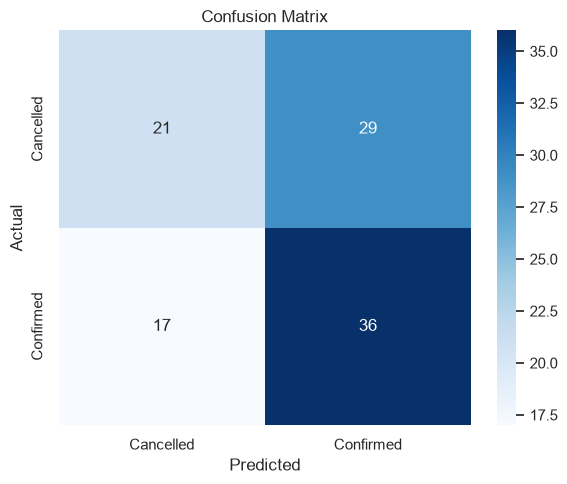

In [6]:
best_name = classification_table.iloc[0]["Model"]
best_model = trained_models[best_name]
pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, pred, target_names=["Cancelled", "Confirmed"]))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Cancelled", "Confirmed"],
            yticklabels=["Cancelled", "Confirmed"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 6. Cross-validation

In [7]:
cv_scores = {}
for name, model in classification_models.items():
    pipeline = Pipeline([("preprocessing", preprocessor), ("model", model)])
    scores = cross_val_score(pipeline, X, y, cv=5, scoring="f1")
    cv_scores[name] = (scores.mean(), scores.std())

display(pd.DataFrame(
    [(name, mean, std) for name, (mean, std) in cv_scores.items()],
    columns=["Model", "Mean F1", "Std F1"]
).sort_values("Mean F1", ascending=False))

F:\Nikk Project\Charusat\Sem - 3\DA\File\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
F:\Nikk Project\Charusat\Sem - 3\DA\File\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
F:\Nikk Project\Charusat\Sem - 3\DA\File\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
F:\Nikk Project\Charusat\Sem - 3\DA\File\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `pr

F:\Nikk Project\Charusat\Sem - 3\DA\File\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Mean F1,Std F1
2,Random Forest,0.568452,0.054904
5,SVM,0.567137,0.090342
3,KNN,0.546388,0.077676
0,Logistic Regression,0.538228,0.034499
1,Decision Tree,0.508203,0.076851
4,Gaussian Naive Bayes,0.063820,0.045856


## 7. Random Forest feature importance

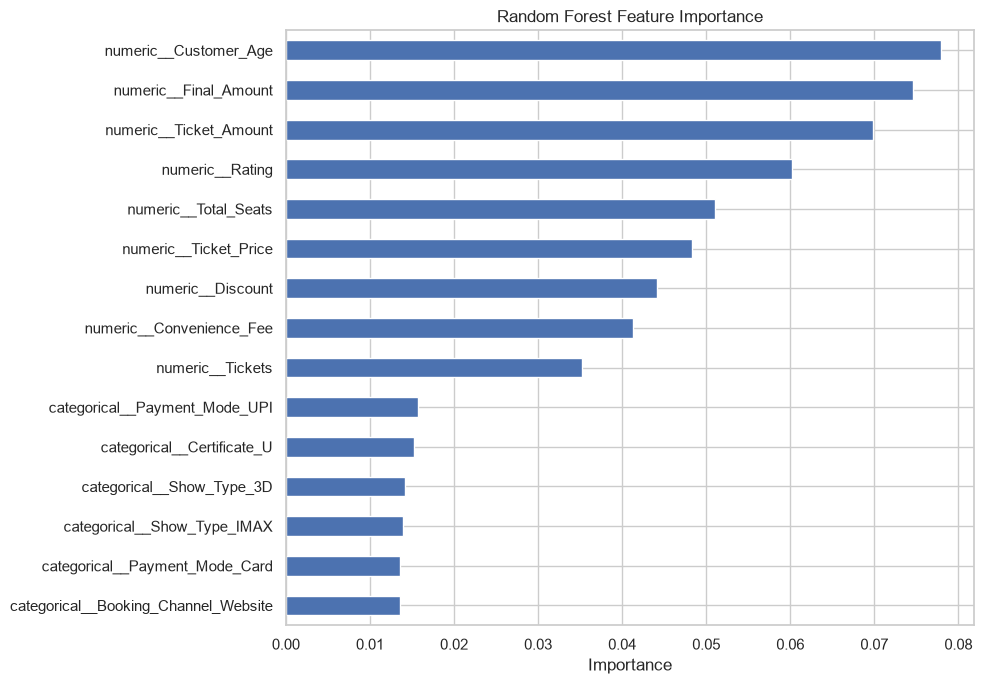

numeric__Customer_Age                   0.077954
numeric__Final_Amount                   0.074589
numeric__Ticket_Amount                  0.069824
numeric__Rating                         0.060154
numeric__Total_Seats                    0.051074
numeric__Ticket_Price                   0.048260
numeric__Discount                       0.044111
numeric__Convenience_Fee                0.041302
numeric__Tickets                        0.035185
categorical__Payment_Mode_UPI           0.015682
categorical__Certificate_U              0.015289
categorical__Show_Type_3D               0.014164
categorical__Show_Type_IMAX             0.013894
categorical__Payment_Mode_Card          0.013624
categorical__Booking_Channel_Website    0.013526
dtype: float64

In [8]:
rf_pipeline = trained_models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]

feature_names = (
    rf_pipeline.named_steps["preprocessing"].get_feature_names_out()
)
importance = pd.Series(rf_model.feature_importances_, index=feature_names)
importance = importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 7))
importance.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
display(importance)

## 8. Regression: predict Final_Amount

In [9]:
regression_df = df.copy()
regression_df = regression_df.dropna(subset=["Final_Amount"])

reg_features = [c for c in features if c != "Final_Amount"]
X_reg = regression_df[reg_features]
y_reg = regression_df["Final_Amount"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=6),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

reg_numeric = [c for c in numeric_features if c in reg_features]
reg_categorical = [c for c in categorical_features if c in reg_features]
reg_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), reg_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), reg_categorical),
])

reg_results = []
trained_regressors = {}
for name, model in regression_models.items():
    pipeline = Pipeline([("preprocessing", reg_preprocessor), ("model", model)])
    pipeline.fit(Xr_train, yr_train)
    pred = pipeline.predict(Xr_test)
    trained_regressors[name] = pipeline
    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2": r2_score(yr_test, pred),
    })

display(pd.DataFrame(reg_results).sort_values("RMSE"))

,Model,MAE,RMSE,R2
2,Decision Tree,36.764040,59.169076,0.988213
1,Ridge,1007.953454,1315.197986,-4.823440
3,Random Forest,492.110922,1953.266626,-11.844595
0,Linear Regression,1399.103577,2622.321321,-22.150970


## 8A. Support Vector Regression (SVR)

In [10]:
svr_pipeline = Pipeline([
    ("preprocessing", reg_preprocessor),
    ("model", SVR(kernel="rbf", C=100, epsilon=0.1)),
])

svr_pipeline.fit(Xr_train, yr_train)
svr_pred = svr_pipeline.predict(Xr_test)

print("SVR MAE:", mean_absolute_error(yr_test, svr_pred))
print("SVR RMSE:", np.sqrt(mean_squared_error(yr_test, svr_pred)))
print("SVR R2:", r2_score(yr_test, svr_pred))

SVR MAE: 102.10102321756865
SVR RMSE: 150.18573020976663
SVR R2: 0.9240627766536645


## 9. Actual versus predicted and residuals

Best regression model: Decision Tree


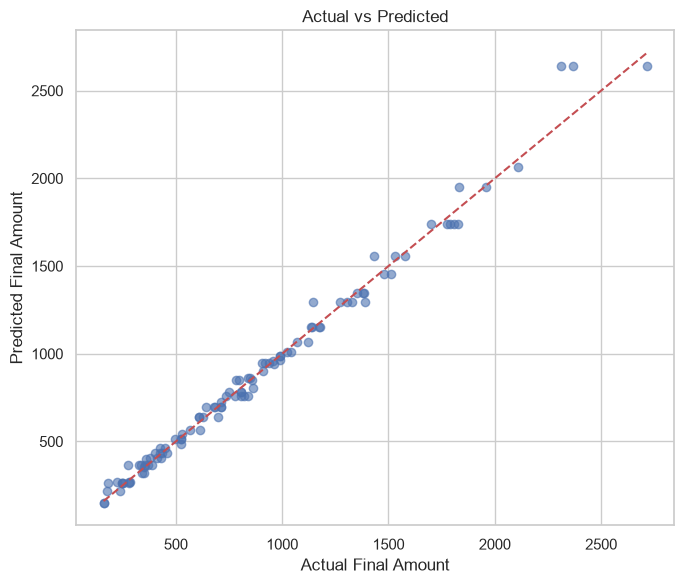

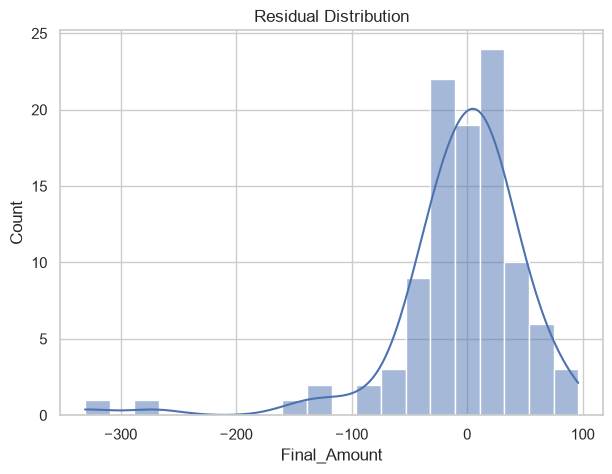

In [11]:
best_reg_name = pd.DataFrame(reg_results).sort_values("RMSE").iloc[0]["Model"]
best_reg = trained_regressors[best_reg_name]
pred = best_reg.predict(Xr_test)
residual = yr_test - pred

print("Best regression model:", best_reg_name)

plt.figure(figsize=(7, 6))
plt.scatter(yr_test, pred, alpha=0.6)
plt.plot([yr_test.min(), yr_test.max()],
         [yr_test.min(), yr_test.max()], "r--")
plt.xlabel("Actual Final Amount")
plt.ylabel("Predicted Final Amount")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.histplot(residual, bins=20, kde=True)
plt.title("Residual Distribution")
plt.show()

## 10. K-Means clustering

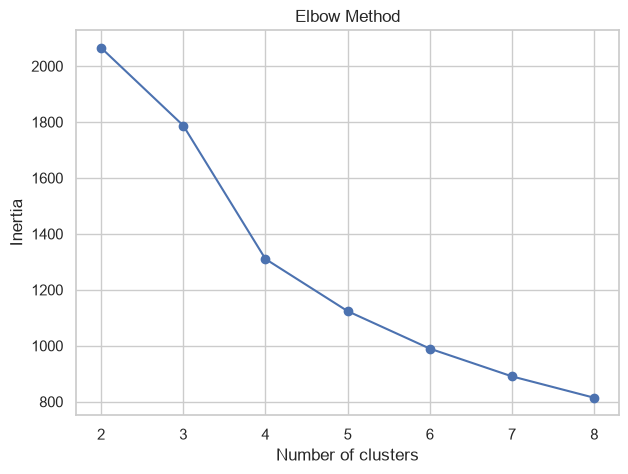

,Customer_Age,Tickets,Final_Amount,Ticket_Price,Rating
Cluster,,,,,
0,36.84,2.09,670.24,403.94,6.15
1,44.00,2.19,722.65,259.34,7.37
2,44.77,5.07,2380.89,339.27,7.42


In [12]:
cluster_columns = [c for c in [
    "Customer_Age", "Tickets", "Final_Amount", "Ticket_Price", "Rating"
] if c in df.columns]

cluster_data = df[cluster_columns].apply(pd.to_numeric, errors="coerce").dropna()
cluster_scaled = StandardScaler().fit_transform(cluster_data)

inertia = []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(cluster_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_data["Cluster"] = kmeans.fit_predict(cluster_scaled)
display(cluster_data.groupby("Cluster").mean().round(2))

## 11. PCA visualization

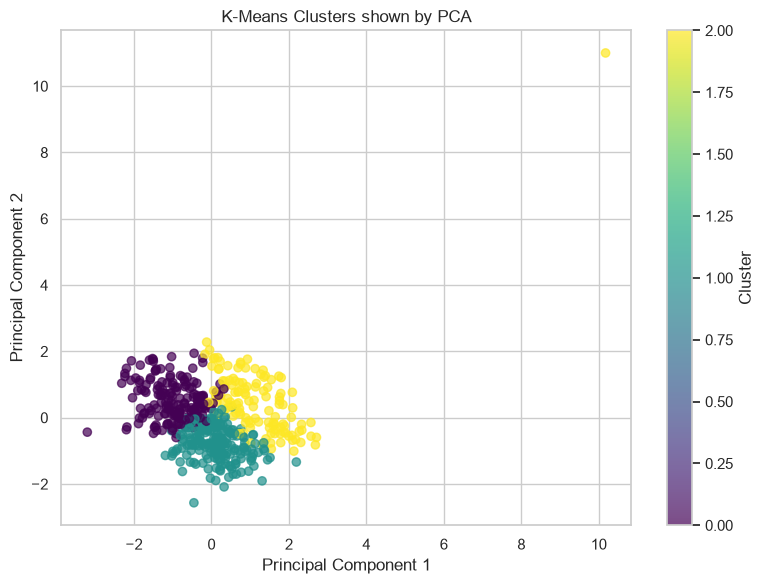

Explained variance: [0.24967251 0.20250954]
Total explained: 0.4521820539883469


In [13]:
pca = PCA(n_components=2)
components = pca.fit_transform(cluster_scaled)

labels = kmeans.labels_
plt.figure(figsize=(8, 6))
scatter = plt.scatter(components[:, 0], components[:, 1],
                      c=labels, cmap="viridis", alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters shown by PCA")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print("Explained variance:", pca.explained_variance_ratio_)
print("Total explained:", pca.explained_variance_ratio_.sum())

## 12. Correlation and overfitting check

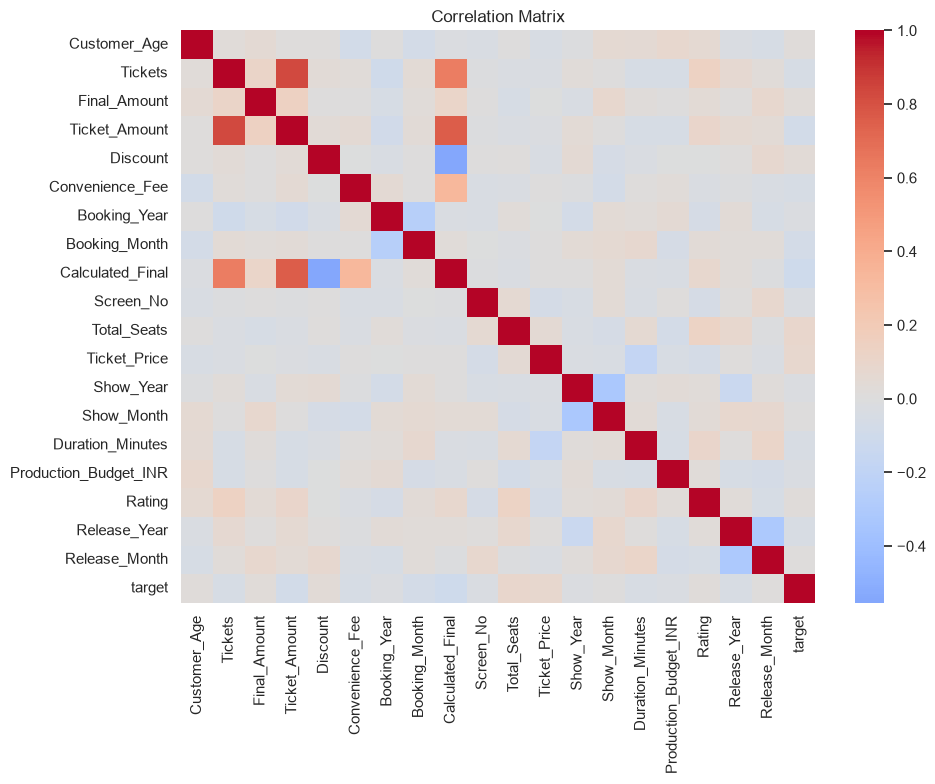

Correlation with booking target:


target           1.000000
Total_Seats      0.091978
Ticket_Price     0.089315
Discount         0.040276
Final_Amount     0.031218
Rating           0.022059
Customer_Age     0.019058
Release_Month    0.013822
Show_Month      -0.001356
Show_Year       -0.015043
Name: target, dtype: float64

In [14]:
numeric_data = df.select_dtypes(include=np.number)
correlation = numeric_data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

if "target" in numeric_data:
    print("Correlation with booking target:")
    display(correlation["target"].sort_values(ascending=False).head(10))

## 13. Save a trained model

In [15]:
import joblib

joblib.dump(best_model, "../Output/best_booking_classifier.joblib")
joblib.dump(best_reg, "../Output/best_final_amount_regressor.joblib")
print("Models saved in ../Output")

Models saved in ../Output
